In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42


In [ ]:
df=pd.read_csv("/content/Loan_status.csv")

In [ ]:
print("Shape:", df.shape)
df.head()


Shape: (500, 10)


,Gender,Married,Education,ApplicantIncome_INR_monthly,CoapplicantIncome_INR_monthly,Credit_Score,LoanAmount_INR,Loan_Term_Months,Property_Area,Loan_Status
0,Male,No,Graduate,25495,0,569,91294,24,Urban,Rejected
1,Male,Yes,Graduate,39461,11608,656,244582,24,Rural,Rejected
2,Male,No,Graduate,25495,0,569,91294,24,Urban,Rejected
3,Male,Yes,Graduate,74346,28888,799,310676,360,Urban,Approved
4,Male,No,Graduate,32166,0,795,84969,60,Semiurban,Approved


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Gender                         500 non-null    object
 1   Married                        500 non-null    object
 2   Education                      500 non-null    object
 3   ApplicantIncome_INR_monthly    500 non-null    int64 
 4   CoapplicantIncome_INR_monthly  500 non-null    int64 
 5   Credit_Score                   500 non-null    int64 
 6   LoanAmount_INR                 500 non-null    int64 
 7   Loan_Term_Months               500 non-null    int64 
 8   Property_Area                  500 non-null    object
 9   Loan_Status                    500 non-null    object
dtypes: int64(5), object(5)
memory usage: 39.2+ KB


In [ ]:
df.isnull().sum()


,0
Gender,0
Married,0
Education,0
ApplicantIncome_INR_monthly,0
CoapplicantIncome_INR_monthly,0
Credit_Score,0
LoanAmount_INR,0
Loan_Term_Months,0
Property_Area,0
Loan_Status,0


In [ ]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome_INR_monthly,500.0,48839.980,26871.809665,12285.0,29164.0,42658.0,61421.0,178891.0
CoapplicantIncome_INR_monthly,500.0,15016.524,17752.033913,0.0,0.0,9382.5,23214.0,90000.0
Credit_Score,500.0,652.262,82.921078,481.0,577.0,656.0,710.0,900.0
LoanAmount_INR,500.0,204752.286,132553.913870,50000.0,91778.5,189129.0,270344.0,900000.0
Loan_Term_Months,500.0,232.800,126.184520,12.0,120.0,300.0,360.0,360.0


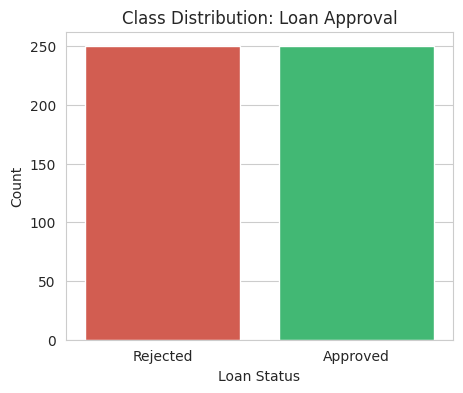

Loan_Status
Rejected    50.0
Approved    50.0
Name: proportion, dtype: float64


In [ ]:

plt.figure(figsize=(5, 4))

sns.countplot(
    x='Loan_Status',
    data=df,
    hue='Loan_Status',
    palette=['#e74c3c', '#2ecc71'],
    legend=False
)

plt.title('Class Distribution: Loan Approval')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.show()

print((df['Loan_Status'].value_counts(normalize=True) * 100).round(2))


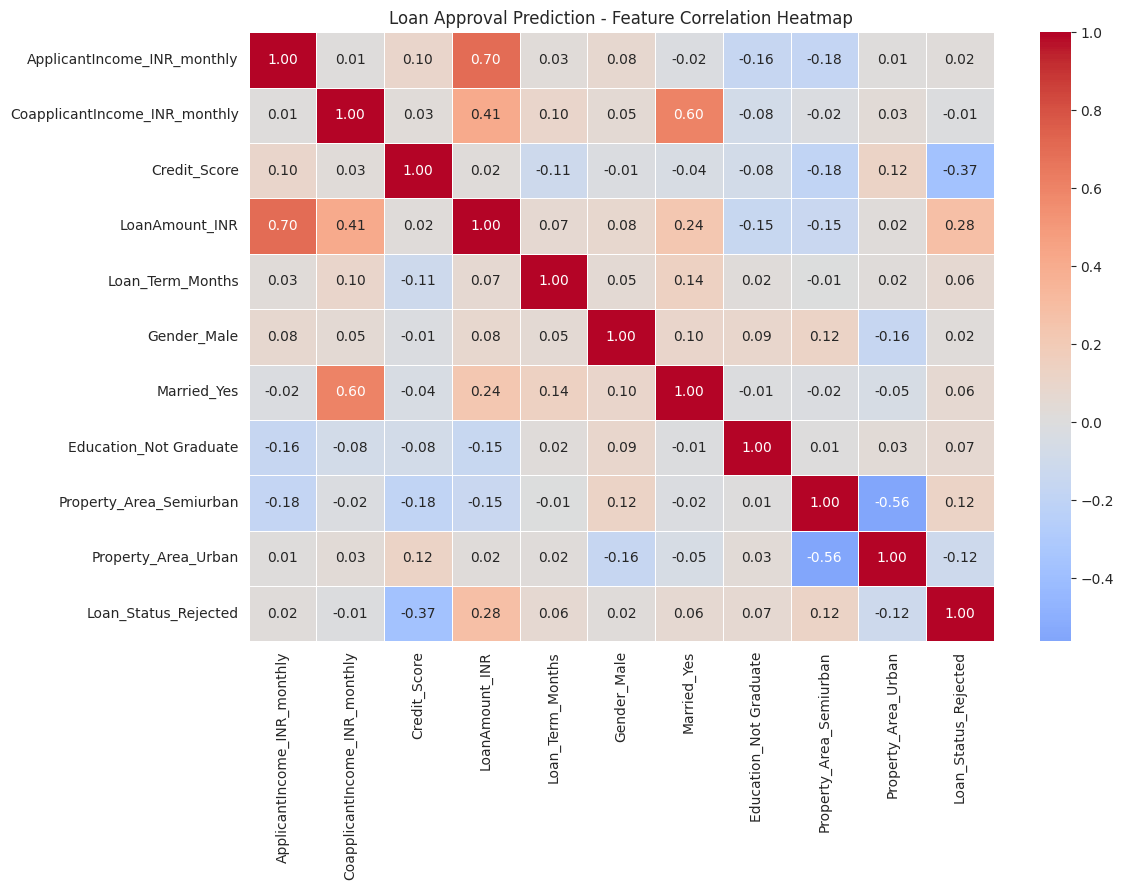

In [ ]:

plt.figure(figsize=(12, 9))

# Convert categorical columns into numeric columns
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

# Calculate correlation
corr = df_encoded.corr()

# Plot heatmap
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Loan Approval Prediction - Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


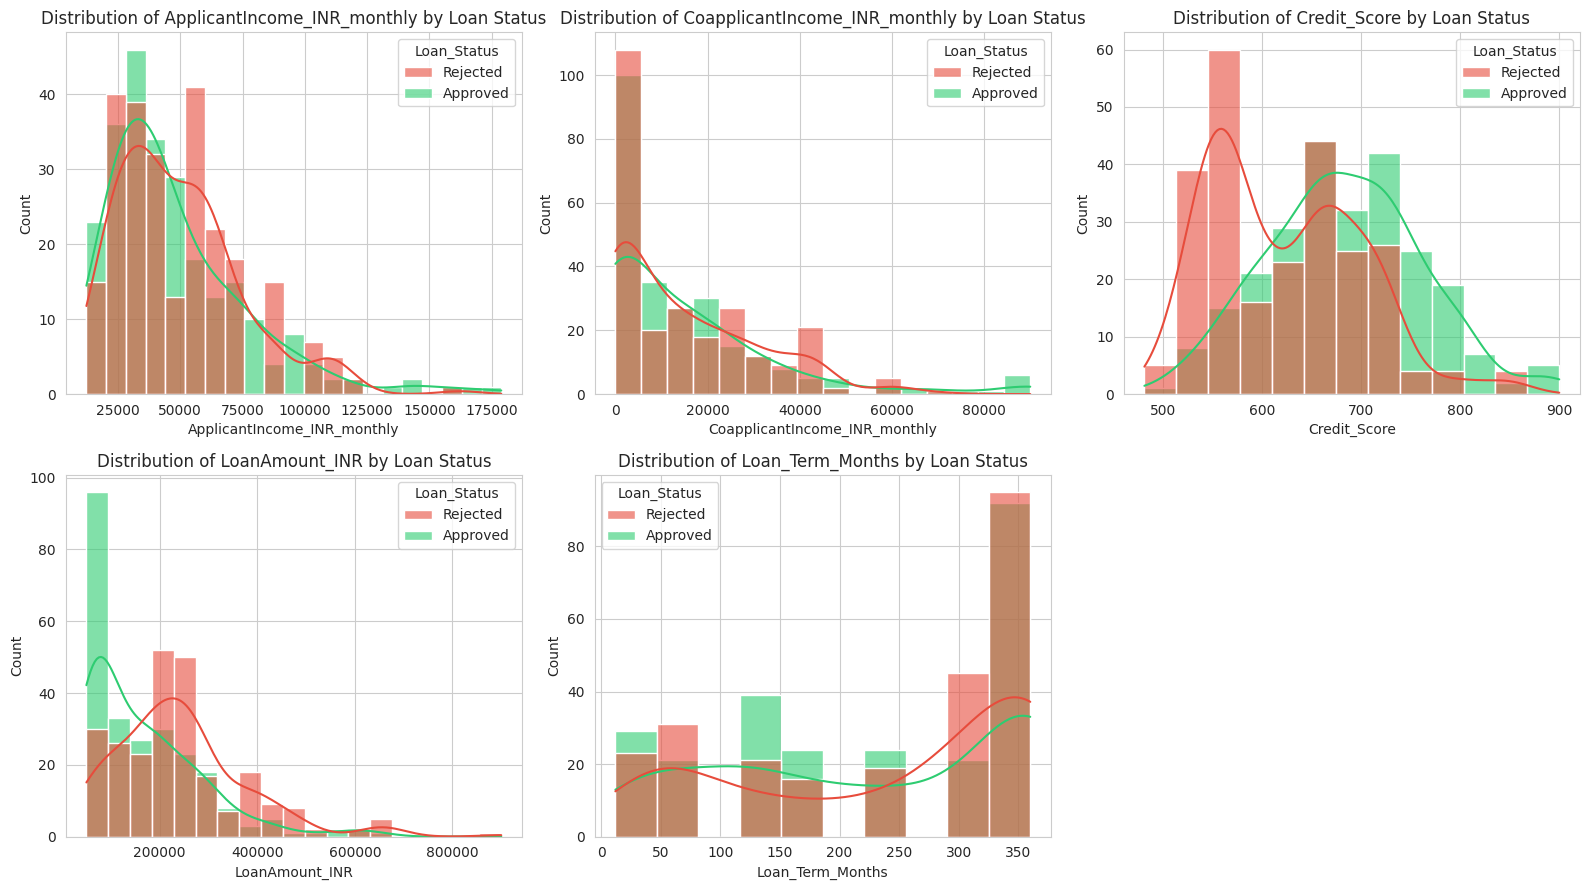

In [ ]:

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

num_features = [
    'ApplicantIncome_INR_monthly',
    'CoapplicantIncome_INR_monthly',
    'Credit_Score',
    'LoanAmount_INR',
    'Loan_Term_Months'
]

for ax, col in zip(axes.flatten(), num_features):
    sns.histplot(
        data=df,
        x=col,
        hue='Loan_Status',
        kde=True,
        ax=ax,
        palette=['#e74c3c', '#2ecc71'],
        alpha=0.6
    )
    ax.set_title(f'Distribution of {col} by Loan Status')

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()


In [ ]:


RANDOM_STATE = 42

# Separate input features and target
X = df.drop(['Loan_Status', 'Loan_ID'], axis=1, errors='ignore')
y = df['Loan_Status']

# Convert categorical features into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)



In [ ]:
dt_gini = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE
)

# Train the Decision Tree model
dt_gini.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

In [ ]:
# Predict loan status
y_pred = dt_gini.predict(X_test)
y_prob = dt_gini.predict_proba(X_test)[:, 1]

# Calculate accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc:.4f}\n")

# Display classification report
print("Classification Report:\n")
print(classification_report(
    y_test,
    y_pred,
    labels=['Rejected', 'Approved'],
    target_names=['Rejected', 'Approved'],
    zero_division=0
))


Test Accuracy: 0.8000

Classification Report:

              precision    recall  f1-score   support

    Rejected       0.89      0.68      0.77        50
    Approved       0.74      0.92      0.82        50

    accuracy                           0.80       100
   macro avg       0.82      0.80      0.80       100
weighted avg       0.82      0.80      0.80       100



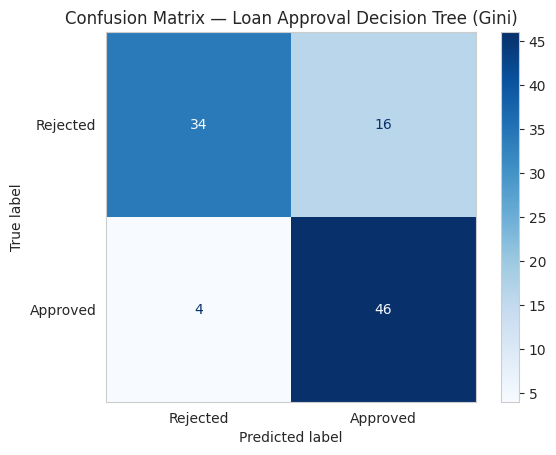

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Rejected', 'Approved']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected', 'Approved']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix — Loan Approval Decision Tree (Gini)')
plt.grid(False)
plt.show()

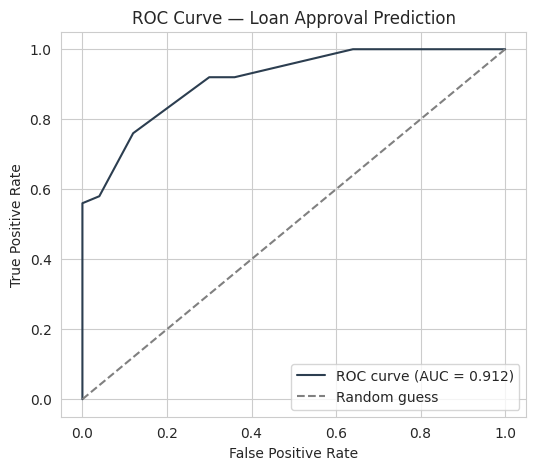

In [ ]:
# Probability of loan approval
approved_index = list(dt_gini.classes_).index('Approved')
y_prob = dt_gini.predict_proba(X_test)[:, approved_index]

# Convert target: Rejected = 0, Approved = 1
y_test_binary = (y_test == 'Approved').astype(int)

# Calculate ROC and AUC
fpr, tpr, _ = roc_curve(y_test_binary, y_prob)
auc_score = roc_auc_score(y_test_binary, y_prob)

# Plot ROC curve
plt.figure(figsize=(6, 5))
plt.plot(
    fpr, tpr,
    label=f'ROC curve (AUC = {auc_score:.3f})',
    color='#2c3e50'
)
plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='gray',
    label='Random guess'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Loan Approval Prediction')
plt.legend()
plt.show()


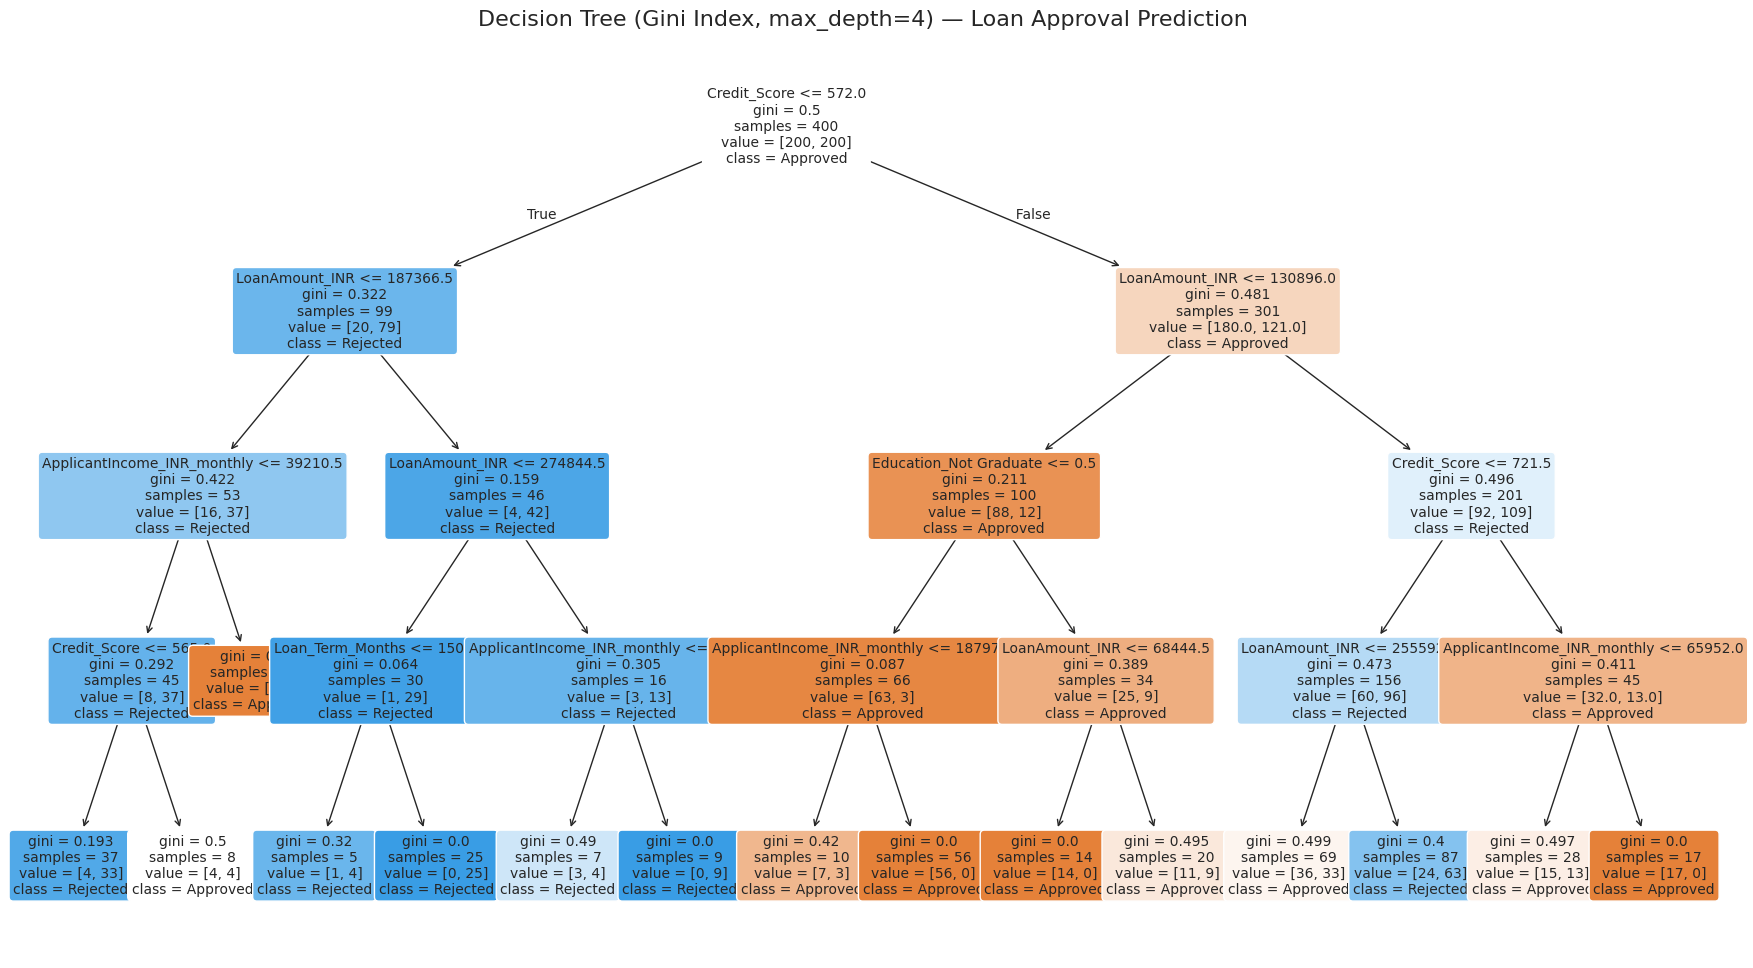

In [ ]:
plt.figure(figsize=(22, 12))

plot_tree(
    dt_gini,
    feature_names=X.columns,
    class_names=[str(c) for c in dt_gini.classes_],
    filled=True,
    rounded=True,
    fontsize=10,
    proportion=False,
    impurity=True
)

plt.title(
    "Decision Tree (Gini Index, max_depth=4) — Loan Approval Prediction",
    fontsize=16
)
plt.show()


In [ ]:
rules_text = export_text(
    dt_gini,
    feature_names=list(X.columns)
)

print("Decision Rules — Loan Approval Prediction\n")
print(rules_text)


Decision Rules — Loan Approval Prediction

|--- Credit_Score <= 572.00
|   |--- LoanAmount_INR <= 187366.50
|   |   |--- ApplicantIncome_INR_monthly <= 39210.50
|   |   |   |--- Credit_Score <= 565.00
|   |   |   |   |--- class: Rejected
|   |   |   |--- Credit_Score >  565.00
|   |   |   |   |--- class: Approved
|   |   |--- ApplicantIncome_INR_monthly >  39210.50
|   |   |   |--- class: Approved
|   |--- LoanAmount_INR >  187366.50
|   |   |--- LoanAmount_INR <= 274844.50
|   |   |   |--- Loan_Term_Months <= 150.00
|   |   |   |   |--- class: Rejected
|   |   |   |--- Loan_Term_Months >  150.00
|   |   |   |   |--- class: Rejected
|   |   |--- LoanAmount_INR >  274844.50
|   |   |   |--- ApplicantIncome_INR_monthly <= 89246.00
|   |   |   |   |--- class: Rejected
|   |   |   |--- ApplicantIncome_INR_monthly >  89246.00
|   |   |   |   |--- class: Rejected
|--- Credit_Score >  572.00
|   |--- LoanAmount_INR <= 130896.00
|   |   |--- Education_Not Graduate <= 0.50
|   |   |   |--- Appl

In [ ]:

def extract_rules(tree, feature_names, class_names):
    tree_ = tree.tree_

    feature_name = [
        feature_names[i] if i != -2 else "undefined!"
        for i in tree_.feature
    ]

    rules = []

    def recurse(node, path):
        if tree_.feature[node] != -2:  # Not a leaf
            name = feature_name[node]
            threshold = tree_.threshold[node]

            left_path = path + [f"{name} <= {threshold:.2f}"]
            recurse(tree_.children_left[node], left_path)

            right_path = path + [f"{name} > {threshold:.2f}"]
            recurse(tree_.children_right[node], right_path)

        else:  # Leaf node
            values = tree_.value[node][0]
            predicted_class = class_names[int(np.argmax(values))]
            n_samples = int(values.sum())
            confidence = values.max() / values.sum() * 100

            rule = (
                "IF " + " AND ".join(path)
                + f" => THEN predict '{predicted_class}'"
                + f" (confidence: {confidence:.1f}%, samples: {n_samples})"
            )
            rules.append(rule)

    recurse(0, [])
    return rules


class_names = [str(c) for c in dt_gini.classes_]
rules = extract_rules(dt_gini, list(X.columns), class_names)

print(f"Total decision rules extracted: {len(rules)}\n")

for i, rule in enumerate(rules, 1):
    print(f"Rule {i}: {rule}\n")


Total decision rules extracted: 15

Rule 1: IF Credit_Score <= 572.00 AND LoanAmount_INR <= 187366.50 AND ApplicantIncome_INR_monthly <= 39210.50 AND Credit_Score <= 565.00 => THEN predict 'Rejected' (confidence: 89.2%, samples: 1)

Rule 2: IF Credit_Score <= 572.00 AND LoanAmount_INR <= 187366.50 AND ApplicantIncome_INR_monthly <= 39210.50 AND Credit_Score > 565.00 => THEN predict 'Approved' (confidence: 50.0%, samples: 1)

Rule 3: IF Credit_Score <= 572.00 AND LoanAmount_INR <= 187366.50 AND ApplicantIncome_INR_monthly > 39210.50 => THEN predict 'Approved' (confidence: 100.0%, samples: 1)

Rule 4: IF Credit_Score <= 572.00 AND LoanAmount_INR > 187366.50 AND LoanAmount_INR <= 274844.50 AND Loan_Term_Months <= 150.00 => THEN predict 'Rejected' (confidence: 80.0%, samples: 1)

Rule 5: IF Credit_Score <= 572.00 AND LoanAmount_INR > 187366.50 AND LoanAmount_INR <= 274844.50 AND Loan_Term_Months > 150.00 => THEN predict 'Rejected' (confidence: 100.0%, samples: 1)

Rule 6: IF Credit_Score <

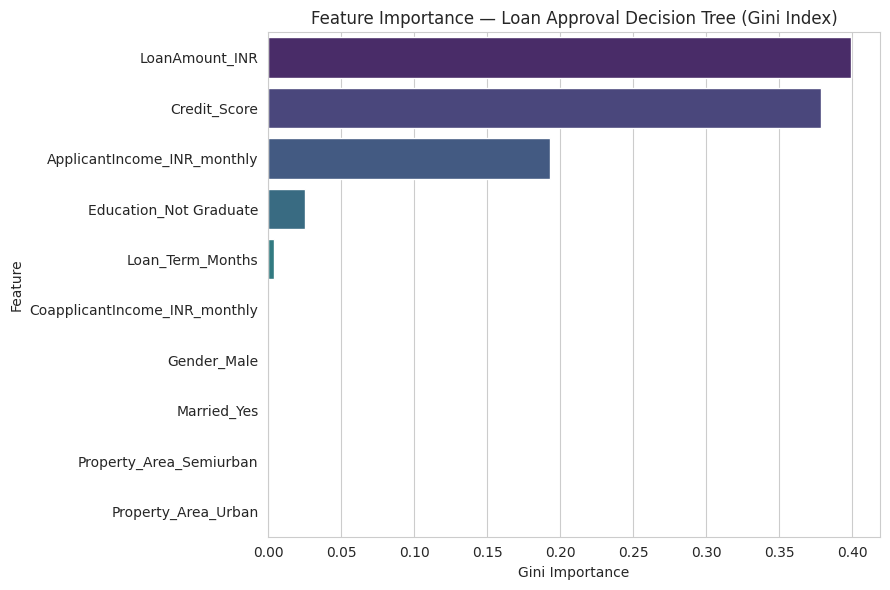

,Feature,Importance
3,LoanAmount_INR,0.399193
2,Credit_Score,0.379033
0,ApplicantIncome_INR_monthly,0.193018
7,Education_Not Graduate,0.024909
4,Loan_Term_Months,0.003848
1,CoapplicantIncome_INR_monthly,0.000000
5,Gender_Male,0.000000
6,Married_Yes,0.000000
8,Property_Area_Semiurban,0.000000
9,Property_Area_Urban,0.000000


In [ ]:

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_gini.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)
plt.title('Feature Importance — Loan Approval Decision Tree (Gini Index)')
plt.xlabel('Gini Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

display(importance_df)


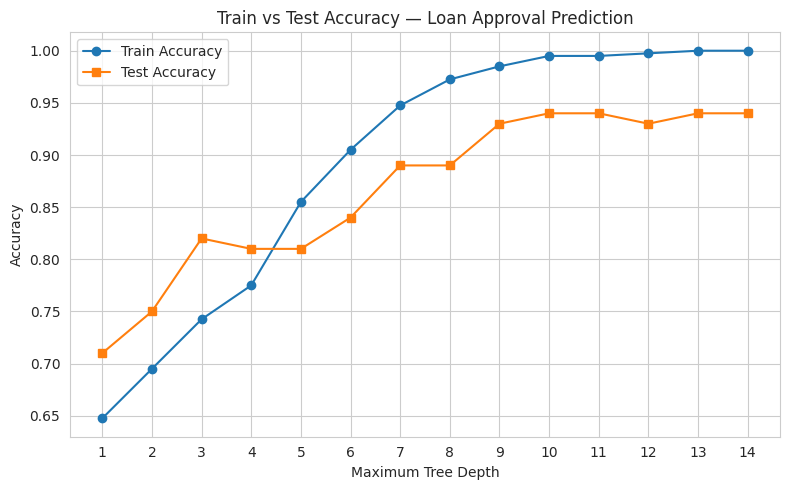

Best max_depth on test set: 10 (Test Accuracy: 0.9400)


In [ ]:
depths = range(1, 15)
train_scores, test_scores = [], []

for d in depths:
    clf = DecisionTreeClassifier(
        criterion='gini',
        max_depth=d,
        random_state=RANDOM_STATE
    )

    clf.fit(X_train, y_train)

    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Train Accuracy')
plt.plot(depths, test_scores, marker='s', label='Test Accuracy')

plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy — Loan Approval Prediction')
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

best_depth = list(depths)[int(np.argmax(test_scores))]

print(
    f"Best max_depth on test set: {best_depth} "
    f"(Test Accuracy: {max(test_scores):.4f})"
)


In [ ]:

# Final Decision Tree using Gini Index
final_gini = DecisionTreeClassifier(
    criterion='gini',
    max_depth=best_depth,
    random_state=RANDOM_STATE
)
final_gini.fit(X_train, y_train)

gini_acc = accuracy_score(
    y_test,
    final_gini.predict(X_test)
)

# Final Decision Tree using Entropy (Information Gain)
final_entropy = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=best_depth,
    random_state=RANDOM_STATE
)
final_entropy.fit(X_train, y_train)

entropy_acc = accuracy_score(
    y_test,
    final_entropy.predict(X_test)
)

# Compare model accuracy
print("Loan Approval Prediction — Model Comparison\n")
print(f"Gini Index Tree          -> Test Accuracy: {gini_acc:.4f}")
print(f"Entropy (Information Gain) -> Test Accuracy: {entropy_acc:.4f}")


Loan Approval Prediction — Model Comparison

Gini Index Tree          -> Test Accuracy: 0.9400
Entropy (Information Gain) -> Test Accuracy: 0.8400


In [ ]:

import pickle
pickle.dump(dt_gini,open('Loan.pkl','wb'))


In [ ]:

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">

    <title>LoanWise | Loan Approval Prediction</title>

    <style>
        :root {
            --primary: #2457e6;
            --primary-dark: #1945c0;
            --navy: #102344;
            --background: #f3f6fc;
            --text: #17243b;
            --muted: #718096;
            --border: #e0e7f1;
            --white: #ffffff;
        }

        * {
            box-sizing: border-box;
            margin: 0;
            padding: 0;
        }

        body {
            font-family: Inter, "Segoe UI", Arial, sans-serif;
            background: var(--background);
            color: var(--text);
            line-height: 1.6;
            min-height: 100vh;
        }

        /* Navigation */
        .navbar {
            background: var(--white);
            border-bottom: 1px solid var(--border);
            padding: 17px 6%;
            display: flex;
            align-items: center;
            justify-content: space-between;
            gap: 15px;
        }

        .brand {
            display: flex;
            align-items: center;
            gap: 11px;
            color: var(--navy);
            font-size: 21px;
            font-weight: 800;
            letter-spacing: -0.5px;
        }

        .brand-icon {
            width: 42px;
            height: 42px;
            display: grid;
            place-items: center;
            background: #eaf0ff;
            color: var(--primary);
            border-radius: 12px;
            font-size: 22px;
        }

        .nav-tag {
            background: #eef2ff;
            color: #3454b4;
            padding: 7px 13px;
            border-radius: 30px;
            font-size: 12px;
            font-weight: 700;
        }

        /* Hero section */
        .hero {
            background: var(--navy);
            color: white;
            padding: 43px 20px 85px;
            text-align: center;
        }

        .hero-label {
            display: inline-block;
            padding: 6px 13px;
            border: 1px solid #3b5276;
            background: #1a3154;
            color: #c7d7ff;
            border-radius: 30px;
            font-size: 12px;
            font-weight: 700;
            letter-spacing: 1px;
            text-transform: uppercase;
            margin-bottom: 15px;
        }

        .hero h1 {
            font-size: clamp(28px, 4vw, 42px);
            line-height: 1.2;
            letter-spacing: -1px;
            margin-bottom: 12px;
        }

        .hero h1 span {
            color: #8eafff;
        }

        .hero p {
            max-width: 570px;
            margin: 0 auto;
            color: #c4d0e4;
            font-size: 15px;
        }

        /* Main content */
        .container {
            width: min(960px, 92%);
            margin: -48px auto 40px;
            position: relative;
        }

        .card {
            background: var(--white);
            border: 1px solid #e9edf5;
            border-radius: 18px;
            padding: 34px;
            box-shadow: 0 15px 45px rgba(16, 35, 68, 0.09);
        }

        .card-heading {
            display: flex;
            align-items: flex-start;
            gap: 14px;
            margin-bottom: 28px;
        }

        .heading-icon {
            flex-shrink: 0;
            width: 46px;
            height: 46px;
            border-radius: 13px;
            background: #edf2ff;
            display: grid;
            place-items: center;
            color: var(--primary);
            font-size: 23px;
        }

        .card-heading h2 {
            color: var(--navy);
            font-size: 22px;
            margin-bottom: 3px;
        }

        .card-heading p {
            color: var(--muted);
            font-size: 14px;
        }

        .section-label {
            font-size: 11px;
            color: #8491a7;
            font-weight: 800;
            letter-spacing: 1.3px;
            text-transform: uppercase;
            margin: 25px 0 15px;
        }

        .section-label:first-child {
            margin-top: 0;
        }

        .form-grid {
            display: grid;
            grid-template-columns: repeat(2, minmax(0, 1fr));
            gap: 22px;
        }

        .field {
            display: flex;
            flex-direction: column;
            gap: 8px;
            min-width: 0;
        }

        .field label {
            font-size: 13px;
            font-weight: 700;
            color: #34425a;
        }

        .input-wrap {
            position: relative;
        }

        input,
        select {
            width: 100%;
            height: 49px;
            padding: 0 14px;
            border: 1px solid #dce3ee;
            border-radius: 9px;
            outline: none;
            background: #fbfcff;
            color: var(--text);
            font-family: inherit;
            font-size: 14px;
            transition: border-color 0.2s, box-shadow 0.2s,
                        background 0.2s;
        }

        input::placeholder {
            color: #a2adbf;
        }

        select:invalid {
            color: #a2adbf;
        }

        input:hover,
        select:hover {
            border-color: #b9c7df;
        }

        input:focus,
        select:focus {
            background: white;
            border-color: var(--primary);
            box-shadow: 0 0 0 3px rgba(36, 87, 230, 0.10);
        }

        .helper {
            color: #8a96a9;
            font-size: 11px;
            margin-top: -3px;
        }

        /* Button */
        .submit-btn {
            width: 100%;
            min-height: 53px;
            margin-top: 32px;
            padding: 14px 20px;
            border: none;
            border-radius: 10px;
            background: var(--primary);
            color: white;
            font-family: inherit;
            font-size: 15px;
            font-weight: 750;
            cursor: pointer;
            display: flex;
            align-items: center;
            justify-content: center;
            gap: 10px;
            box-shadow: 0 6px 15px rgba(36, 87, 230, 0.20);
            transition: background 0.2s, transform 0.2s;
        }

        .submit-btn:hover {
            background: var(--primary-dark);
            transform: translateY(-1px);
        }

        .submit-btn:active {
            transform: translateY(0);
        }

        .button-arrow {
            font-size: 19px;
        }

        /* Result */
        .result {
            margin-top: 28px;
            padding: 26px 20px;
            text-align: center;
            border-radius: 14px;
            animation: appear 0.35s ease;
        }

        .result-icon {
            width: 52px;
            height: 52px;
            display: grid;
            place-items: center;
            margin: 0 auto 12px;
            border-radius: 50%;
            font-size: 25px;
            font-weight: bold;
        }

        .result h2 {
            font-size: 13px;
            text-transform: uppercase;
            letter-spacing: 1px;
            margin-bottom: 6px;
        }

        .result .status {
            font-size: 29px;
            font-weight: 800;
            margin: 2px 0 8px;
        }

        .result p {
            font-size: 14px;
        }

        .approved {
            background: #ecfdf3;
            border: 1px solid #b8edcb;
            color: #17663a;
        }

        .approved .result-icon {
            background: #d0f6dd;
        }

        .rejected {
            background: #fff0f0;
            border: 1px solid #facaca;
            color: #a52626;
        }

        .rejected .result-icon {
            background: #ffdada;
        }

        .error {
            margin-top: 22px;
            padding: 15px 17px;
            background: #fff7ed;
            color: #9a3412;
            border: 1px solid #fed7aa;
            border-radius: 9px;
            font-size: 14px;
        }

        .disclaimer {
            margin-top: 24px;
            padding: 15px 17px;
            border-radius: 9px;
            background: #f6f8fc;
            border: 1px solid #e9edf5;
            color: #758197;
            font-size: 12px;
            line-height: 1.7;
        }

        .disclaimer strong {
            color: #4c5b72;
        }

        footer {
            padding: 5px 20px 28px;
            text-align: center;
            color: #8995a8;
            font-size: 12px;
        }

        @keyframes appear {
            from {
                opacity: 0;
                transform: translateY(8px);
            }
            to {
                opacity: 1;
                transform: translateY(0);
            }
        }

        @media (max-width: 650px) {
            .navbar {
                padding: 13px 5%;
            }

            .brand {
                font-size: 18px;
            }

            .brand-icon {
                width: 37px;
                height: 37px;
            }

            .nav-tag {
                font-size: 10px;
                padding: 6px 9px;
            }

            .hero {
                padding: 35px 18px 75px;
            }

            .hero p {
                font-size: 13px;
            }

            .container {
                width: 94%;
                margin-top: -42px;
            }

            .card {
                padding: 23px 19px;
                border-radius: 14px;
            }

            .card-heading h2 {
                font-size: 20px;
            }

            .form-grid {
                grid-template-columns: 1fr;
                gap: 18px;
            }

            .section-label {
                margin-top: 23px;
            }
        }

        @media (prefers-reduced-motion: reduce) {
            *, *::before, *::after {
                animation-duration: 0.01ms !important;
                transition-duration: 0.01ms !important;
            }
        }
    </style>
</head>

<body>

    <nav class="navbar">
        <div class="brand">
            <div class="brand-icon">▤</div>
            <span>LoanWise</span>
        </div>

        <div class="nav-tag">ML CLASSIFICATION</div>
    </nav>

    <section class="hero">
        <div class="hero-label">Smart Loan Assessment</div>

        <h1>Loan Approval <span>Prediction</span></h1>

        <p>
            Enter the applicant details below to generate a prediction
            using a Decision Tree classification model.
        </p>
    </section>

    <main class="container">
        <section class="card">

            <div class="card-heading">
                <div class="heading-icon">✎</div>
                <div>
                    <h2>Applicant Information</h2>
                    <p>Complete all fields to evaluate the application.</p>
                </div>
            </div>

            <form method="POST" action="/">

                <div class="section-label">01 — Personal Information</div>

                <div class="form-grid">

                    <div class="field">
                        <label for="Gender">Gender</label>
                        <select id="Gender" name="Gender" required>
                            <option value="" disabled selected>Select gender</option>
                            <option value="Male">Male</option>
                            <option value="Female">Female</option>
                        </select>
                    </div>

                    <div class="field">
                        <label for="Married">Marital Status</label>
                        <select id="Married" name="Married" required>
                            <option value="" disabled selected>Select marital status</option>
                            <option value="Yes">Married</option>
                            <option value="No">Not married</option>
                        </select>
                    </div>

                    <div class="field">
                        <label for="Education">Education</label>
                        <select id="Education" name="Education" required>
                            <option value="" disabled selected>Select education level</option>
                            <option value="Graduate">Graduate</option>
                            <option value="Not Graduate">Not graduate</option>
                        </select>
                    </div>

                    <div class="field">
                        <label for="Property_Area">Property Area</label>
                        <select id="Property_Area" name="Property_Area" required>
                            <option value="" disabled selected>Select property area</option>
                            <option value="Urban">Urban</option>
                            <option value="Semiurban">Semiurban</option>
                            <option value="Rural">Rural</option>
                        </select>
                    </div>

                </div>

                <div class="section-label">02 — Financial Information</div>

                <div class="form-grid">

                    <div class="field">
                        <label for="ApplicantIncome_INR_monthly">
                            Applicant Monthly Income (₹)
                        </label>
                        <input
                            type="number"
                            id="ApplicantIncome_INR_monthly"
                            name="ApplicantIncome_INR_monthly"
                            min="0"
                            step="any"
                            placeholder="Enter monthly income"
                            required>
                    </div>

                    <div class="field">
                        <label for="CoapplicantIncome_INR_monthly">
                            Co-applicant Monthly Income (₹)
                        </label>
                        <input
                            type="number"
                            id="CoapplicantIncome_INR_monthly"
                            name="CoapplicantIncome_INR_monthly"
                            min="0"
                            step="any"
                            placeholder="Enter co-applicant income"
                            required>
                    </div>

                    <div class="field">
                        <label for="Credit_Score">Credit Score</label>
                        <input
                            type="number"
                            id="Credit_Score"
                            name="Credit_Score"
                            min="300"
                            max="900"
                            step="1"
                            placeholder="Enter credit score"
                            required>
                        <span class="helper">Accepted range: 300–900</span>
                    </div>

                    <div class="field">
                        <label for="LoanAmount_INR">Requested Loan Amount (₹)</label>
                        <input
                            type="number"
                            id="LoanAmount_INR"
                            name="LoanAmount_INR"
                            min="0"
                            step="any"
                            placeholder="Enter loan amount"
                            required>
                    </div>

                    <div class="field">
                        <label for="Loan_Term_Months">Loan Term (Months)</label>
                        <input
                            type="number"
                            id="Loan_Term_Months"
                            name="Loan_Term_Months"
                            min="1"
                            step="1"
                            placeholder="Enter loan duration"
                            required>
                    </div>

                </div>

                <button type="submit" class="submit-btn">
                    Predict Loan Status
                    <span class="button-arrow">→</span>
                </button>

            </form>

            {% if prediction %}
                <div class="result {% if prediction == 'Approved' %}approved{% else %}rejected{% endif %}">

                    <div class="result-icon">
                        {% if prediction == 'Approved' %}
                            ✓
                        {% else %}
                            !
                        {% endif %}
                    </div>

                    <h2>Prediction Result</h2>

                    <div class="status">{{ prediction }}</div>

                    <p>
                        Model confidence:
                        <strong>{{ probability }}%</strong>
                    </p>

                </div>
            {% endif %}

            {% if error %}
                <div class="error">
                    <strong>Unable to predict:</strong> {{ error }}
                </div>
            {% endif %}


        </section>
    </main>

    <footer>
        LoanWise · Decision Tree Classification · Gini Index
    </footer>

</body>
</html>


In [ ]:

from flask import Flask, render_template, request
import pickle
import pandas as pd

app = Flask(__name__)

# Load the trained Decision Tree model
with open("loan.pkl", "rb") as file:
    model = pickle.load(file)


@app.route("/", methods=["GET", "POST"])
def home():
    prediction = None
    probability = None
    error = None

    if request.method == "POST":
        try:
            # Collect input values from HTML form
            applicant = {
                "Gender": request.form["Gender"],
                "Married": request.form["Married"],
                "Education": request.form["Education"],
                "ApplicantIncome_INR_monthly": float(
                    request.form["ApplicantIncome_INR_monthly"]
                ),
                "CoapplicantIncome_INR_monthly": float(
                    request.form["CoapplicantIncome_INR_monthly"]
                ),
                "Credit_Score": float(
                    request.form["Credit_Score"]
                ),
                "LoanAmount_INR": float(
                    request.form["LoanAmount_INR"]
                ),
                "Loan_Term_Months": float(
                    request.form["Loan_Term_Months"]
                ),
                "Property_Area": request.form["Property_Area"]
            }

            input_df = pd.DataFrame([applicant])

            # Encode categorical columns
            input_df = pd.get_dummies(
                input_df,
                drop_first=True,
                dtype=int
            )

            # Get the exact feature names from the trained model
            feature_names = model.feature_names_in_

            # Match training columns and their order
            input_df = input_df.reindex(
                columns=feature_names,
                fill_value=0
            )

            # Predict loan status
            prediction = model.predict(input_df)[0]

            # Probability of predicted class
            probabilities = model.predict_proba(input_df)[0]
            predicted_index = list(model.classes_).index(prediction)
            probability = round(
                probabilities[predicted_index] * 100, 2
            )

        except (ValueError, KeyError) as e:
            error = "Please enter valid values in all fields."

        except AttributeError:
            error = (
                "Model feature names are unavailable. "
                "Please retrain and save the model using "
                "a pandas DataFrame with column names."
            )

    return render_template(
        "index.html",
        prediction=prediction,
        probability=probability,
        error=error
    )


if __name__ == "__main__":
    app.run(debug=True)
